# Лабораторная работа 3
## Визуализация данных (Pandas, Matplotlib, Seaborn)

**ФИО:** Хатыпов Тимур Радикович
**Группа:** ЕТ-216
**Файл данных:** StudentsPerformance.csv

In [15]:
from google.colab import files
uploaded = files.upload()

Saving StudentsPerformance.csv to StudentsPerformance (1).csv


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

df = pd.read_csv("StudentsPerformance.csv")
print(df.head())
print(df.shape)
print(df.info())

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
(1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null C

In [17]:
print(df["parental level of education"].value_counts())
#какие значения там есть и сколько раз каждое встречается



parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64


## Блок 1. Pandas

Построены встроенные графики Pandas для категориальных и числовых столбцов.

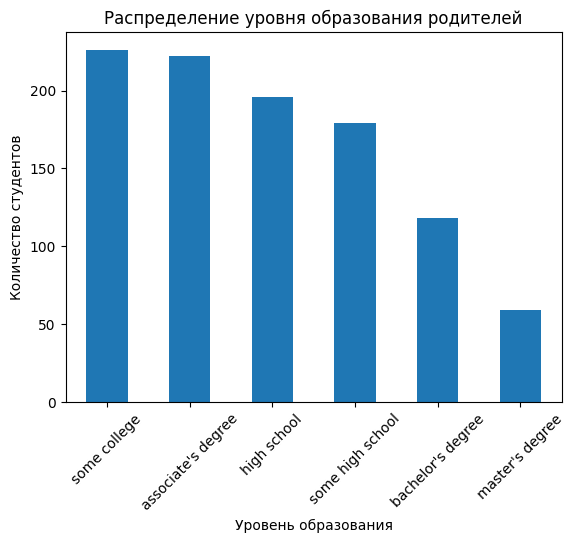

In [18]:
df["parental level of education"].value_counts().plot(kind="bar")
plt.title("Распределение уровня образования родителей")
plt.xlabel("Уровень образования")
plt.ylabel("Количество студентов")
plt.xticks(rotation=45)
plt.show()

## Pandas. Задание 1. Столбчатая диаграмма

Построена столбчатая диаграмма для столбца parental level of education
через встроенный метод Pandas: value_counts().plot(kind="bar").

Самые частые категории: some college (226) и associate's degree (222).
Реже всего встречается master's degree (59).

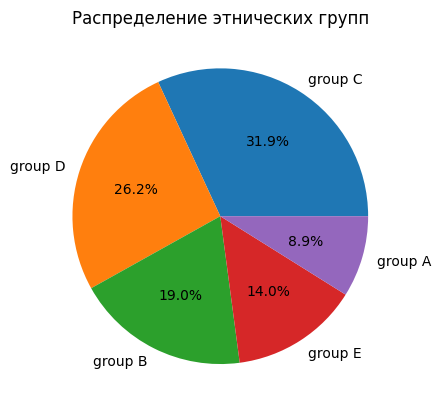

In [19]:
df["race/ethnicity"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Распределение этнических групп")
plt.ylabel("")  # убираем подпись по Y
plt.show()

## Pandas. Задание 2. Круговая диаграмма

Построена круговая диаграмма для столбца race/ethnicity через
plot(kind="pie", autopct="%1.1f%%").

Распределение этнических групп:
- group C — 31.9%
- group D — 26.2%
- group B — 19.0%
- group E — 14.0%
- group A — 8.9%

Самые крупные группы — C и D (вместе около 58%).

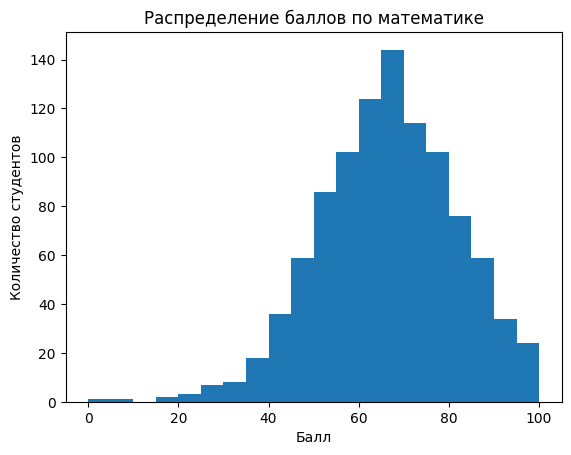

In [20]:
df["math score"].plot(kind="hist", bins=20)
plt.title("Распределение баллов по математике")
plt.xlabel("Балл")
plt.ylabel("Количество студентов")
plt.show()

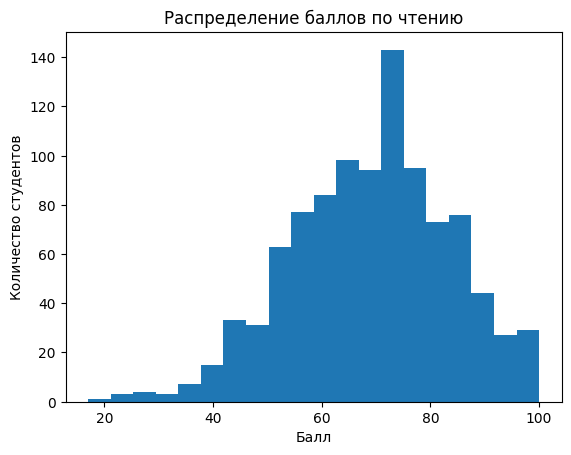

In [21]:
df["reading score"].plot(kind="hist", bins=20)
plt.title("Распределение баллов по чтению")
plt.xlabel("Балл")
plt.ylabel("Количество студентов")
plt.show()

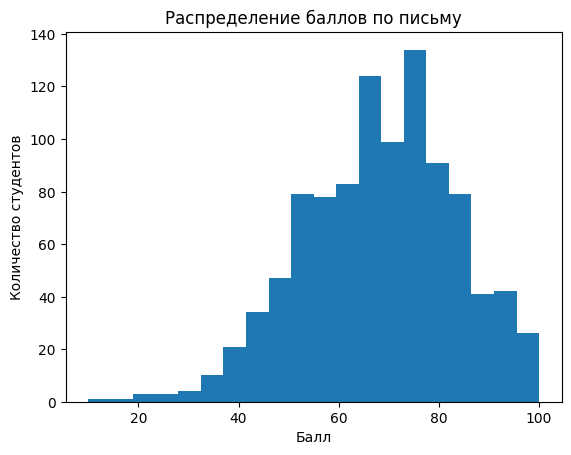

In [22]:
df["writing score"].plot(kind="hist", bins=20)
plt.title("Распределение баллов по письму")
plt.xlabel("Балл")
plt.ylabel("Количество студентов")
plt.show()

## Pandas. Задание 3. Гистограммы числовых столбцов

Построены три гистограммы — по одной на каждый числовой столбец:
math score, reading score, writing score. Для каждой использован
plot(kind="hist", bins=20).

Все три распределения близки к нормальному с пиком в районе
65–75 баллов. Math score имеет более длинный левый хвост —
есть студенты с очень низкими баллами. Reading и writing
распределены более симметрично. Большинство студентов получают
50–85 баллов по каждому предмету.

## Блок 2. Matplotlib

Построена сетка из 6 графиков через subplots(3×2): косинусы, boxplot,
комбинированный график, текст, 3D-рассеяние, круговая диаграмма.

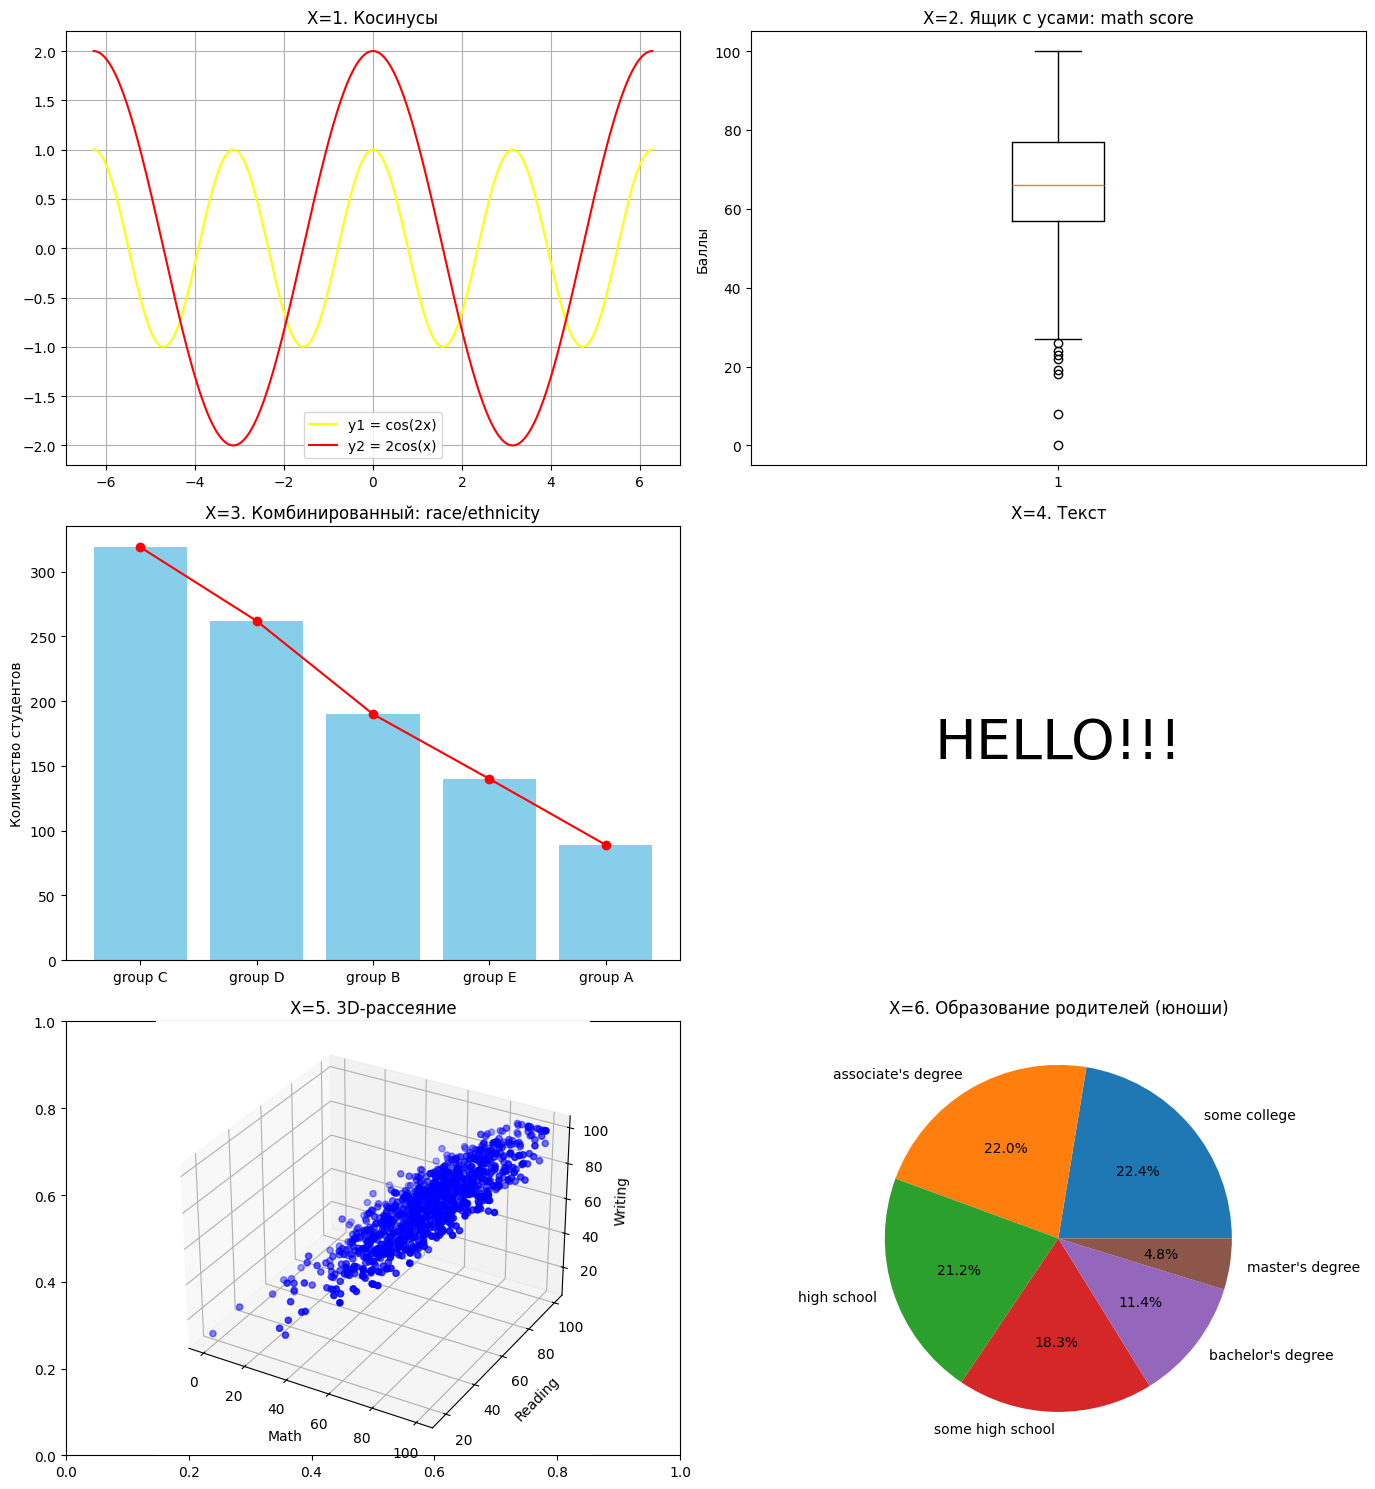

In [23]:
from mpl_toolkits.mplot3d import Axes3D

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# X=1: два косинуса
x = np.linspace(-2 * np.pi, 2 * np.pi, 500)
axes[0, 0].plot(x, np.cos(2 * x), color="yellow", label="y1 = cos(2x)")
axes[0, 0].plot(x, 2 * np.cos(x), color="red", label="y2 = 2cos(x)")
axes[0, 0].set_title("X=1. Косинусы")
axes[0, 0].grid(True)
axes[0, 0].legend()

# X=2: boxplot
axes[0, 1].boxplot(df["math score"])
axes[0, 1].set_title("X=2. Ящик с усами: math score")
axes[0, 1].set_ylabel("Баллы")

# X=3: комбинированный
counts = df["race/ethnicity"].value_counts()
axes[1, 0].bar(counts.index, counts.values, color="skyblue")
axes[1, 0].plot(counts.index, counts.values, color="red", marker="o")
axes[1, 0].set_title("X=3. Комбинированный: race/ethnicity")
axes[1, 0].set_ylabel("Количество студентов")

# X=4: текст
axes[1, 1].text(0.5, 0.5, "HELLO!!!", fontsize=40, ha="center", va="center")
axes[1, 1].set_title("X=4. Текст")
axes[1, 1].axis("off")

# X=5: 3D-рассеяние
ax3d = fig.add_subplot(3, 2, 5, projection="3d")
ax3d.scatter(df["math score"], df["reading score"], df["writing score"], c="blue")
ax3d.set_title("X=5. 3D-рассеяние")
ax3d.set_xlabel("Math")
ax3d.set_ylabel("Reading")
ax3d.set_zlabel("Writing")

# X=6: круговая для юношей
male_df = df[df["gender"] == "male"]
male_counts = male_df["parental level of education"].value_counts()
axes[2, 1].pie(male_counts.values, labels=male_counts.index, autopct="%1.1f%%")
axes[2, 1].set_title("X=6. Образование родителей (юноши)")

plt.tight_layout()  # авто-выравнивание
plt.show()

## Блок Matplotlib

Построены 6 графиков в сетке subplots(3×2):

X=1. Два косинуса: cos(2x) (жёлтый) и 2cos(x) (красный). Первый
колеблется чаще, второй — выше по амплитуде. Сетка, легенда.

X=2. Ящик с усами для math score. Медиана ≈ 66, ящик от 60 до 78,
выбросы — студенты с баллами около 0–20. Ответ на вопрос:
выбросы есть.

X=3. Комбинированный график для race/ethnicity: столбики + линия.
Виден тренд падения от group C к group A.

X=4. Текст HELLO!!! в центре ячейки.

X=5. 3D-рассеяние для math + reading + writing. Облако точек
вытянуто вдоль диагонали — все три оценки сильно связаны.

X=6. Круговая диаграмма для юношей (gender=male) по уровню
образования родителей. Самая частая категория — some college (22.4%).

## Блок 3. Seaborn

Построены pairplot, pairplot с кластеризацией по полу и тепловая карта корреляций.

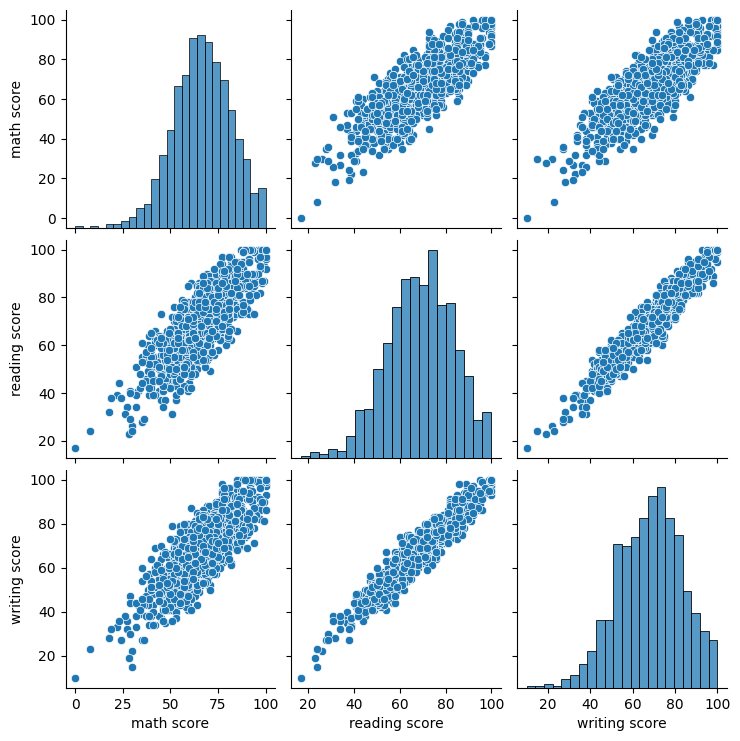

In [24]:
sns.pairplot(df)
plt.show()

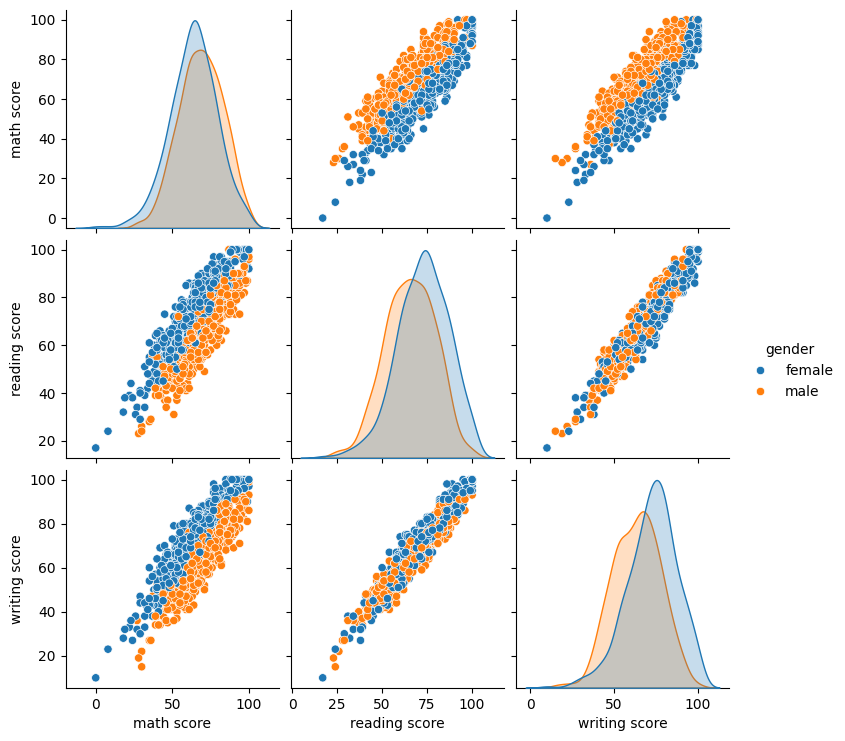

In [25]:
sns.pairplot(df, hue="gender", diag_kind="kde")
plt.show()

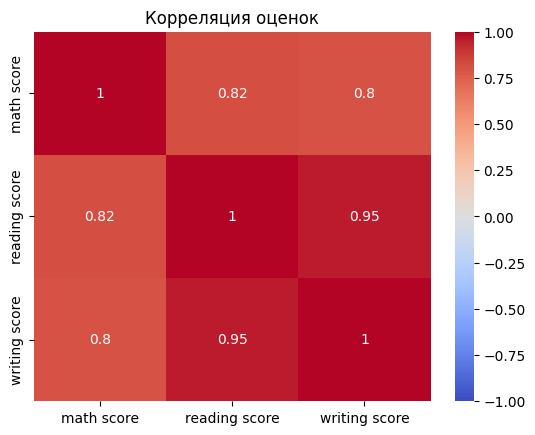

In [26]:
corr_matrix = df[["math score", "reading score", "writing score"]].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция оценок")
plt.show()

## Блок Seaborn

### Задание 1. pairplot с гистограммами
Построена сетка 3×3 для трёх числовых столбцов (math, reading, writing).
По диагонали — гистограммы распределения, вне диагонали — scatter-графики.
Все три оценки сильно коррелируют: облака точек вытянуты по диагонали.

### Задание 2. pairplot с hue=gender и KDE
Добавлена кластеризация по полу и KDE-кривые по диагонали.
Видно, что по чтению и письму девушки в среднем получают более высокие
баллы (пик кривых сдвинут вправо). По математике различия минимальны.

### Задание 3. Тепловая карта корреляций
Построена heatmap матрицы корреляций:
- math ↔ reading = 0.82
- math ↔ writing = 0.80
- reading ↔ writing = 0.95

Самая сильная связь — между чтением и письмом (0.95). Это ожидаемо,
потому что это родственные навыки. Корреляция математики с ними чуть ниже.